# Results

## In plain words
Three things, each checked:

1. **Phase recovery on the sample files.** Gerchberg-Saxton recovers a field that explains
   both dispersed intensity traces. The files are synthetic, so this shows the code is
   consistent, not that it works on lab hardware.
2. **The SEALS port matches the lab MATLAB** to about 1e-10 for the same default case.
3. **Rayleigh-Debye fix.** The MATLAB Rayleigh-Debye-Gans formula leaves the form factor
   unsquared; squaring it makes the result agree with exact Mie theory where it should.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, matplotlib.pyplot as plt
from dgs import real_data, gs_core
from seals import scattering as S
plt.rcParams.update({"figure.dpi": 110})
OKABE = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00"]
STYLES = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1))]

## 1. Phase recovery on the six sample files
The error shown is the mismatch on arm 1, the trace *not* enforced last in each iteration.
`gs_core.retrieve_phase` reports error on arm 2 instead, which is ~0 after one iteration no
matter what, so it can't tell you if the answer is right.

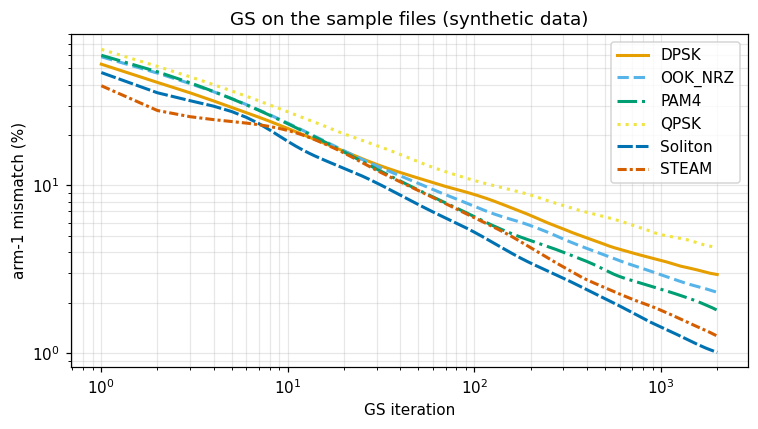

DPSK     mismatch after 2000 iterations: 2.9 %
OOK_NRZ  mismatch after 2000 iterations: 2.3 %
PAM4     mismatch after 2000 iterations: 1.8 %
QPSK     mismatch after 2000 iterations: 4.3 %
Soliton  mismatch after 2000 iterations: 1.0 %
STEAM    mismatch after 2000 iterations: 1.3 %
Figure: one line per modulation format, mismatch falling from ~40-65 % to ~1-4 % on log-log axes.


In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
final = {}
for i, f in enumerate(real_data.list_files()):
    d, E, hist = real_data.retrieve(f, n_iter=2000)
    final[d["standard"]] = hist[-1]
    ax.loglog(np.arange(1, hist.size + 1), 100 * hist, color=OKABE[i], ls=STYLES[i], lw=2, label=d["standard"])
ax.set_xlabel("GS iteration"); ax.set_ylabel("arm-1 mismatch (%)"); ax.grid(alpha=0.3, which="both")
ax.set_title("GS on the sample files (synthetic data)"); ax.legend()
plt.tight_layout(); plt.show()
for k, v in final.items():
    print(f"{k:8s} mismatch after 2000 iterations: {100*v:.1f} %")
print("Figure: one line per modulation format, mismatch falling from ~40-65 % to ~1-4 % on log-log axes.")

## 2. SEALS port vs the lab MATLAB (default case)

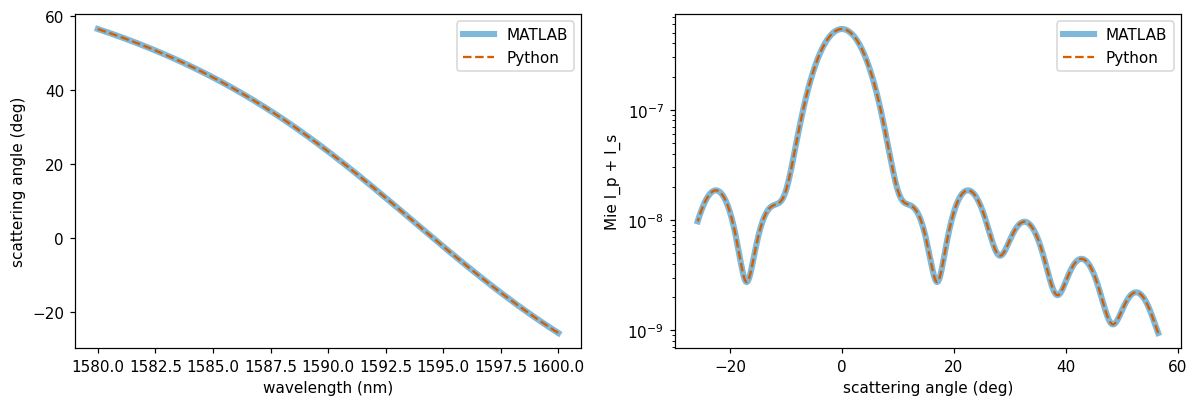

max relative difference: angle 5.2e-10, Mie intensity 3.3e-14
Figure: Python (dashed) lies on top of MATLAB (thick) in both panels.


In [3]:
M = np.loadtxt("../tests/data/matlab_defaults.csv", delimiter=",")
LAM, Y, TH, IP, IS, TP, TS, IRD = M.T
p = S.DEFAULTS
y, th, _ = S.seals(p["d"], p["D"], p["a"], p["dcorr"], p["P"], p["NA"], LAM)
sig, ip, is_, *_ = S.mie(p["npar"], p["nmed"], p["dia"], LAM.mean(), np.deg2rad(TH), p["r"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(LAM*1e9, TH, color=OKABE[4], lw=4, alpha=0.5, label="MATLAB")
ax[0].plot(LAM*1e9, th + p["mangle"], color=OKABE[5], ls="--", lw=1.5, label="Python")
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("scattering angle (deg)"); ax[0].legend()
ax[1].semilogy(TH, IP + IS, color=OKABE[4], lw=4, alpha=0.5, label="MATLAB")
ax[1].semilogy(TH, ip + is_, color=OKABE[5], ls="--", lw=1.5, label="Python")
ax[1].set_xlabel("scattering angle (deg)"); ax[1].set_ylabel("Mie I_p + I_s"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"max relative difference: angle {np.max(np.abs((th+p['mangle']-TH)/TH)):.1e}, Mie intensity {np.max(np.abs((ip+is_-IP-IS)/(IP+IS))):.1e}")
print("Figure: Python (dashed) lies on top of MATLAB (thick) in both panels.")

## 3. Rayleigh-Debye: lab formula vs corrected vs exact Mie
A 3 µm sphere with relative index 1.002, where Rayleigh-Debye-Gans is supposed to work.
Curves are normalized at the smallest angle so only the *shape* is compared.
`mie()` keeps the lab convention where I_p + I_s is twice the unpolarized intensity,
which doesn't matter after normalizing.

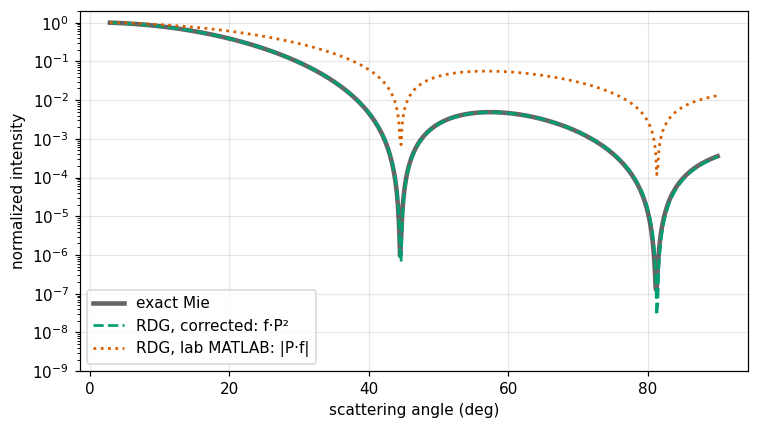

Figure: the corrected curve follows Mie's lobes and nulls; the lab formula falls off far too slowly.


In [4]:
lam, th = 1590e-9, np.linspace(0.05, np.pi/2, 600)
_, ip, is_, *_ = S.mie(1.002, 1.0, 3000e-9, lam, th, 0.1)
mie_I = ip + is_
fix = S.rayleigh_debye(3000e-9, lam, 1.0, 1.002, th, 0.1)
lab = S.rayleigh_debye_matlab(3000e-9, lam, 1.0, 1.002, th, 0.1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.degrees(th), mie_I/mie_I[0], color="k", lw=3, alpha=0.6, label="exact Mie")
ax.semilogy(np.degrees(th), fix/fix[0], color=OKABE[2], ls="--", lw=1.8, label="RDG, corrected: f·P²")
ax.semilogy(np.degrees(th), lab/lab[0], color=OKABE[5], ls=":", lw=1.8, label="RDG, lab MATLAB: |P·f|")
ax.set_xlabel("scattering angle (deg)"); ax.set_ylabel("normalized intensity"); ax.set_ylim(1e-9, 2)
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("Figure: the corrected curve follows Mie's lobes and nulls; the lab formula falls off far too slowly.")